# Fitting $\sigma_y$, $K$ and $n$ to a flow curve: identifiability, weighting and uncertainty

Fitting the Herschel–Bulkley (HB) law to a measured flow curve looks like a routine three-parameter regression. It is not. The yield stress and the flow index trade off against each other along a long, curved valley of nearly equal misfit, so that the fitted yield stress depends on the range of shear rates, on how the residuals are weighted and on the few low-rate points, which are also the points most affected by wall slip and slow transients. This notebook makes the problem visible with the synthetic data of Fig. 7 of the review, shows how Mullineux's observation that the model is *linear* in $\sigma_y$ and $K$ at fixed $n$ reduces the fit to a one-dimensional search, and computes profile-likelihood intervals for the yield stress as in Supplementary Fig. S5. It closes with practical advice from Sec. VI of the review.

### Where this is in the review
- **Sec. VI D** (Identifiability of the HB triplet), with **Fig. 7**; **Sec. VI A** (operational definitions of the yield stress, Table VII); **Sec. VI E** (the dominance of systematic error); **Sec. VI F** (propagating parameter uncertainty, **Eq. (17)**).
- Supplementary Note **S6** (statistical identification): **S6 A** likelihood and weighting, **Eq. (S12)**; **S6 B** profile fitting with physical constraints, **Eq. (S13)** and **Fig. S4**; **S6 C** sensitivity, covariance and design, **Eq. (S14)** and **Fig. S5**. Also Note **S5 B** (calibration window and prediction spread) and **S18** (reporting checklist).
- Scripts `scripts/fig07_fitting.py`, `scripts/figS4_mullineux.py`, `scripts/figS5_uncertainty.py`; data `data/fitting_illustration.json`, `data/figure_data/fig07_fitting*.csv`, `figS4_mullineux.csv`, `figS5_uncertainty.csv`.
- A complete implementation of Mullineux's determinant method for measured flow curves (a Python package with tests, confidence intervals and model comparison, and a browser app) is available at **https://github.com/ktwyw/herschel-bulkley-determinant-fit**.

### Learning objectives
After working through this notebook you should be able to
1. fit the HB law with logarithmic and linear residuals, over full and truncated rate windows, and explain why the answers differ;
2. map the residual surface in the $(\sigma_y, n)$ plane and recognize the valley that makes the problem ill-conditioned;
3. reduce the fit to a one-dimensional problem in $n$ (Mullineux 2008), handle the constraint $\sigma_y\ge0$ correctly, and relate the conditioning to the spread of $\dot\gamma^{\,n}$ over the data;
4. treat the choice of weights as a statement about the measurement noise;
5. compute a profile-likelihood interval for $\sigma_y$ and compare it with the local (Wald) approximation;
6. list the checks that a defensible HB characterization needs beyond a good fit.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))

import hbstyle as hs   # house style, palette C and HB helper functions (we never call hs.save)
C = hs.C
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())
from scipy.optimize import curve_fit, least_squares

def hb(g, sy, K, n):
    """HB stress on the yielded branch, Eq. (3)."""
    return sy + K * g**n

data folder found: True


## 1. The synthetic flow curve of Fig. 7

Synthetic data have one big advantage: we know the truth. Fig. 7 uses $\sigma_y = 10$ Pa, $K = 2$ Pa s$^{0.5}$, $n = 0.5$, 26 shear rates evenly spaced in $\log\dot\gamma$ from $10^{-2}$ to $10^{3}$ s$^{-1}$, and 5% multiplicative Gaussian noise, $\sigma_i = \sigma(\dot\gamma_i)(1 + 0.05\,\varepsilon_i)$. We generate exactly the same numbers as `scripts/fig07_fitting.py` (random seed 1). The data assume slip-free, stationary, homogeneous flow; in an experiment those conditions must be established independently, and they are hardest to satisfy at exactly the low rates that constrain $\sigma_y$.

In [2]:
TRUE = dict(sy=10.0, K=2.0, n=0.5)
rng = np.random.default_rng(1)
gd = np.logspace(-2, 3, 26)                                         # 1/s
tau = hb(gd, **TRUE) * (1 + 0.05 * rng.standard_normal(gd.size))   # Pa
pd.DataFrame({"shear rate (1/s)": gd, "stress (Pa)": tau}).head(8).round(4)

,shear rate (1/s),stress (Pa)
0,0.0100,10.3762
1,0.0158,10.6729
2,0.0251,10.4874
3,0.0398,9.7215
4,0.0631,10.9778
5,0.1000,10.8698
6,0.1585,10.5064
7,0.2512,11.3221


## 2. Three reasonable fits, three different yield stresses

Fig. 7(a) compares three choices that a careful analyst might make:

1. **(i) logarithmic residuals, all rates**: minimize $\sum_i[\ln\sigma(\dot\gamma_i) - \ln\sigma_i]^2$, appropriate for constant *relative* errors (as generated here);
2. **(ii) logarithmic residuals, $\dot\gamma\ge10$ s$^{-1}$ only**: the same, after discarding the low-rate points (perhaps suspected of slip);
3. **(iii) linear residuals, all rates**: minimize $\sum_i[\sigma(\dot\gamma_i) - \sigma_i]^2$, which implicitly assumes constant *absolute* errors.

All three use the same bounds and starting point as the script.

In [3]:
model = lambda g, a, b, c: a + b * g**c
bounds = ([0, 1e-6, 0.05], [50, 100, 2]); p0 = [5, 1, 0.7]
logmodel = lambda g, a, b, c: np.log(model(g, a, b, c))
p_log, _ = curve_fit(logmodel, gd, np.log(tau), p0=p0, bounds=bounds)
high = gd >= 10.0
p_high, _ = curve_fit(logmodel, gd[high], np.log(tau[high]), p0=p0, bounds=bounds)
p_lin, _ = curve_fit(model, gd, tau, p0=p0, bounds=bounds)
FITS = {"(i) log, all rates": p_log, "(ii) log, high rates": p_high, "(iii) linear, all rates": p_lin}
table = pd.DataFrame(FITS, index=["sigma_y (Pa)", "K (Pa s^n)", "n"]).T
table.loc["true"] = [TRUE["sy"], TRUE["K"], TRUE["n"]]
table.round(3)

,sigma_y (Pa),K (Pa s^n),n
"(i) log, all rates",10.005,2.110,0.483
"(ii) log, high rates",7.794,3.136,0.426
"(iii) linear, all rates",9.457,2.711,0.442
true,10.000,2.000,0.500


In [4]:
# The stored values used for Fig. 7 (written by scripts/fig07_fitting.py)
stored = json.loads((DATA / "fitting_illustration.json").read_text())
for key, p in zip(["log_full", "log_high", "linear_full"], FITS.values()):
    assert np.allclose(p, stored[key], rtol=1e-6), key
print("fits agree with data/fitting_illustration.json to 1e-6")

fits agree with data/fitting_illustration.json to 1e-6


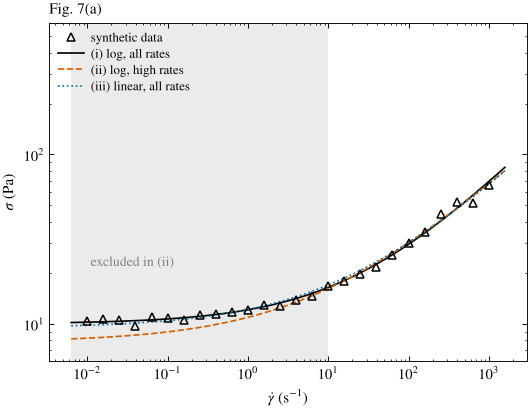

In [5]:
CF = {"(i) log, all rates": (C["black"], "-", "o", "white"), "(ii) log, high rates": (C["red"], "--", "s", C["red"]),
      "(iii) linear, all rates": (C["blue"], ":", "D", C["cyan"])}
gfine = np.logspace(-2.2, 3.2, 300)
fig, ax = plt.subplots(figsize=(5.6, 4.0))
ax.axvspan(1e-2 / 1.6, 10.0, color=C["lightgrey"], alpha=0.35, lw=0)
ax.text(0.011, 22, "excluded in (ii)", color=C["grey"], fontsize=9)
ax.loglog(gd, tau, "^", ms=5, mfc="none", mec="k", label="synthetic data", zorder=5)
for lab, p in FITS.items():
    col, ls, *_ = CF[lab]
    ax.loglog(gfine, model(gfine, *p), color=col, ls=ls, label=lab)
ax.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", ylim=(6, 600))
ax.legend(loc="upper left", fontsize=8.5); ax.set_title("Fig. 7(a)", loc="left", fontsize=10); plt.show()

All three curves pass through the data, yet the extrapolated yield stresses range from 7.8 to 10.0 Pa. Removing the low-rate data shifts $\sigma_y$ by more than 20% although fit (ii) "looks" fine; switching to linear residuals lets the large stresses at high rates dominate the fit. Nothing in a plot of the fitted curve warns you.

## 3. The residual valley in the $(\sigma_y, n)$ plane

To see why, fix $\sigma_y$ and $n$ and choose the best $K$. With relative weights $w_i = 1/\sigma_i$ the residuals are $r_i = w_i(\sigma_i - \sigma_y - K\dot\gamma_i^{\,n})$, which is linear in $K$, so the optimal $K$ has the closed form

$$K^*(\sigma_y, n) = \frac{\sum_i w_i^2\,\dot\gamma_i^{\,n}(\sigma_i-\sigma_y)}{\sum_i w_i^2\,\dot\gamma_i^{\,2n}}.$$

Fig. 7(b) maps the root-mean-square relative residual $\sqrt{\overline{r_i^2}}$ (in percent) over a $161\times161$ grid. We compute the same grid as the script and compare it with the stored `fig07_fitting_rms_residual_grid.csv`.

In [6]:
TY = np.linspace(0, 20, 161); NN = np.linspace(0.2, 1.0, 161)
w = 1.0 / tau
RMS = np.zeros((NN.size, TY.size))
for i, nn in enumerate(NN):
    X = gd**nn
    for j, tt in enumerate(TY):
        yv = tau - tt
        Kopt = max(np.sum(w**2 * X * yv) / np.sum(w**2 * X * X), 1e-9)     # K* (kept positive)
        RMS[i, j] = np.sqrt(np.mean(((yv - Kopt * X) * w)**2)) * 100
grid = pd.read_csv(FIGDATA / "fig07_fitting_rms_residual_grid.csv", comment="#")
ref_rms = grid.pivot(index="n", columns="sigma_y_Pa", values="rms_residual_percent").values
assert ref_rms.shape == RMS.shape
diff = np.max(np.abs(ref_rms - RMS))
assert diff < 1e-6
print(f"RMS grid ({RMS.size} points) agrees with fig07_fitting_rms_residual_grid.csv; "
      f"largest difference {diff:.1e} percentage points (tolerance 1e-6)")

RMS grid (25921 points) agrees with fig07_fitting_rms_residual_grid.csv; largest difference 5.0e-09 percentage points (tolerance 1e-6)


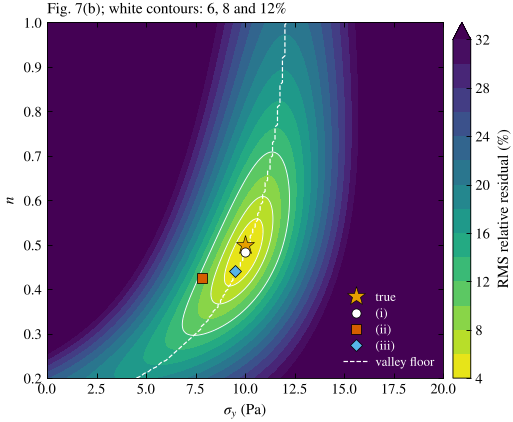

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
cs = ax.contourf(TY, NN, RMS, levels=np.linspace(4, 32, 15), cmap="viridis_r", extend="max")
ax.contour(TY, NN, RMS, levels=[6, 8, 12], colors="white", linewidths=0.6)
cb = fig.colorbar(cs, ax=ax, pad=0.02); cb.set_label("RMS relative residual (%)")
ax.plot(TRUE["sy"], TRUE["n"], "*", color=C["orange"], ms=13, mec="k", mew=0.4, label="true", zorder=3)
for lab, p in FITS.items():
    col, ls, mk, mcol = CF[lab]
    ax.plot(p[0], p[2], mk, color=mcol, ms=6, mec="k", mew=0.5, label=lab.split(")")[0] + ")", zorder=4)
# the bottom of the valley: for each n, the sigma_y with the smallest residual
ax.plot(TY[np.argmin(RMS, axis=1)], NN, color="white", lw=0.8, ls="--", label="valley floor")
ax.set(xlabel=r"$\sigma_y$ (Pa)", ylabel=r"$n$"); ax.minorticks_off()
leg = ax.legend(loc="lower right", fontsize=8.5, labelcolor="white")
ax.set_title("Fig. 7(b); white contours: 6, 8 and 12%", loc="left", fontsize=10); plt.show()

The 6% contour encloses a long, curved valley running from low $\sigma_y$ and low $n$ to high $\sigma_y$ and high $n$. Anywhere along its floor the misfit changes little, so small changes in the data (noise, a truncated window, a different weighting) move the optimum a long way along it. This is what "ill-conditioned" means here. The dashed "valley floor" line is our own addition to the figure.

We can also check the panel (b) markers against the figure data:

In [8]:
ref7 = pd.read_csv(FIGDATA / "fig07_fitting.csv", comment="#")
for lab, p in FITS.items():
    r = ref7[(ref7.panel == "(b)") & (ref7.series == lab.split(")")[0] + ")")]
    assert np.allclose([r.x.iloc[0], r.y.iloc[0]], [p[0], p[2]], rtol=1e-6)
    r = ref7[(ref7.panel == "(a)") & (ref7.series == lab)].sort_values("index")
    assert np.allclose(r.y.values, model(gfine, *p), rtol=1e-6)
r = ref7[(ref7.panel == "(a)") & (ref7.series == "synthetic data")].sort_values("index")
assert np.allclose(r.x.values, gd, rtol=1e-9) and np.allclose(r.y.values, tau, rtol=1e-9)
print("Fig. 7 panels (a) and (b): data, fitted curves and markers agree with fig07_fitting.csv (rtol 1e-6)")

Fig. 7 panels (a) and (b): data, fitted curves and markers agree with fig07_fitting.csv (rtol 1e-6)


## 4. Mullineux's reduction to a one-dimensional problem

At fixed $n$ the HB law is **linear** in the two remaining parameters. With $z_i = (\dot\gamma_i/\dot\gamma_*)^n$, weights $w_i$ and amplitude $A = K\dot\gamma_*^{\,n}$ (we take $\dot\gamma_* = 1$ s$^{-1}$, so $A = K$), the weighted least-squares problem has the normal equations

$$\begin{pmatrix}\sum w_i & \sum w_iz_i\\ \sum w_iz_i & \sum w_iz_i^2\end{pmatrix}\begin{pmatrix}\sigma_y\\ A\end{pmatrix} = \begin{pmatrix}\sum w_i\sigma_i\\ \sum w_iz_i\sigma_i\end{pmatrix}. \tag{S13}$$

Solving them in closed form for every $n$ gives $\sigma_y(n)$, $K(n)$ and the reduced objective $F(n) = \min_{\sigma_y,K}\mathrm{SSE}$. The three-parameter fit becomes a scan in one variable (Mullineux 2008), which exposes the valley of Fig. 7(b) as the curve $(\sigma_y(n), n)$.

Two details matter (Supplementary Note S6 B):
- **Constraints.** If the unconstrained solution has $\sigma_y<0$ or $K<0$, the constrained optimum lies on the boundary and must be *recomputed there* (e.g. $\sigma_y = 0$ and the one-parameter fit for $K$). Clipping a coefficient after an unconstrained fit is not the constrained least-squares solution.
- **Conditioning.** The determinant of the matrix in Eq. (S13) equals $(\sum w_i)^2\,\mathrm{Var}_w(z)$, where $\mathrm{Var}_w$ is the weighted variance of $z_i = \dot\gamma_i^{\,n}$. A narrow rate window makes the columns nearly collinear and the problem nearly singular, whatever the optimizer.

Here the weights $w_i$ multiply squared residuals, so "relative weighting" means $w_i = 1/\sigma_i^2$ (the script writes the same thing as residuals scaled by $1/\sigma_i$).

In [9]:
def mullineux_step(n, g, s, w, constrained=True):
    """Best (sigma_y, K) at fixed n from the normal equations (S13); returns (SSE, sigma_y, K)."""
    z = g**n
    M = np.array([[w.sum(), (w * z).sum()], [(w * z).sum(), (w * z * z).sum()]])
    b = np.array([(w * s).sum(), (w * z * s).sum()])
    sy, K = np.linalg.solve(M, b)
    if constrained and (sy < 0 or K < 0):
        # recompute on the boundary instead of clipping
        cand = []
        K0 = (w * z * s).sum() / (w * z * z).sum()          # sigma_y = 0
        if K0 >= 0: cand.append((0.0, K0))
        cand.append(((w * s).sum() / w.sum(), 0.0))          # K = 0 (a constant stress)
        sy, K = min(cand, key=lambda p: np.sum(w * (s - p[0] - p[1] * z)**2))
    return np.sum(w * (s - sy - K * z)**2), sy, K

def mullineux_scan(g, s, w, NN, constrained=True):
    return np.array([mullineux_step(nn, g, s, w, constrained) for nn in NN])

NNs = np.linspace(0.2, 1.0, 400)
WEIGHTS = {"absolute weighting": np.ones_like(tau), "relative weighting": 1 / tau**2}
# constrained scan (sigma_y >= 0 recomputed on the boundary), as in scripts/figS4_mullineux.py
scan = {lab: mullineux_scan(gd, tau, wt, NNs, constrained=True) for lab, wt in WEIGHTS.items()}
for lab, res in scan.items():
    i = np.argmin(res[:, 0])
    print(f"{lab:20s}: n* = {NNs[i]:.3f}, sigma_y(n*) = {res[i, 1]:.2f} Pa, K(n*) = {res[i, 2]:.3f} Pa s^n")

absolute weighting  : n* = 0.443, sigma_y(n*) = 9.47 Pa, K(n*) = 2.699 Pa s^n
relative weighting  : n* = 0.481, sigma_y(n*) = 9.98 Pa, K(n*) = 2.120 Pa s^n


Each weighting has a unique minimum, at $n^* = 0.44$ (absolute) and $0.48$ (relative), as in Fig. S4(a). The relative-weighting optimum is close to the logarithmic-residual fit (i) of Sec. 2 (for 5% noise, relative weights and logarithmic residuals are nearly equivalent), a useful check that the one-dimensional scan finds the same valley minimum as the three-parameter optimizer. Now we reproduce Fig. S4 and compare with `figS4_mullineux.csv`.

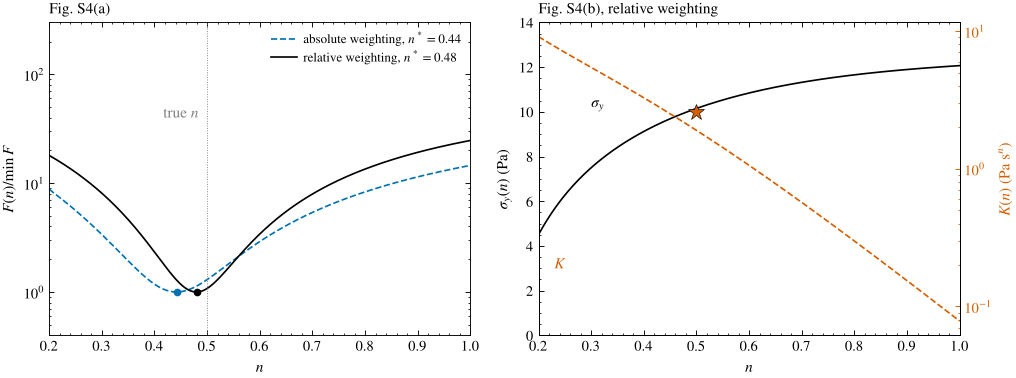

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.7))
mine = {}
for (lab, res), col, ls in zip(scan.items(), [C["blue"], C["black"]], ["--", "-"]):
    F = res[:, 0] / res[:, 0].min(); i = np.argmin(res[:, 0])
    ax1.semilogy(NNs, F, color=col, ls=ls, label=f"{lab}, $n^*={NNs[i]:.2f}$")
    ax1.plot(NNs[i], 1.0, "o", color=col, ms=4)
    mine[("(a)", lab)] = F; mine[("(a)", lab + ": minimum n*")] = NNs[i]
ax1.axvline(TRUE["n"], color=C["grey"], lw=0.6, ls=":"); ax1.text(0.485, 40, "true $n$", color=C["grey"], ha="right")
ax1.set(xlabel="$n$", ylabel=r"$F(n)/\min F$", xlim=(0.2, 1.0), ylim=(0.4, 300)); ax1.legend(fontsize=8.5)
ax1.set_title("Fig. S4(a)", loc="left", fontsize=10)
res = scan["relative weighting"]
ax2.plot(NNs, res[:, 1], color="k", label=r"$\sigma_y(n)$")
ax2b = ax2.twinx(); ax2b.semilogy(NNs, res[:, 2], color=C["red"], ls="--")
ax2b.set_ylabel(r"$K(n)$ (Pa s$^{n}$)", color=C["red"]); ax2b.tick_params(axis="y", colors=C["red"], which="both")
ax2.plot(TRUE["n"], TRUE["sy"], "*", color=C["red"], ms=11, mec="k", mew=0.4)
ax2.set(xlabel="$n$", ylabel=r"$\sigma_y(n)$ (Pa)", xlim=(0.2, 1.0), ylim=(0, 14))
ax2.text(0.30, 10.2, r"$\sigma_y$"); ax2.text(0.23, 3.0, "$K$", color=C["red"])
ax2.set_title("Fig. S4(b), relative weighting", loc="left", fontsize=10)
fig.tight_layout(); plt.show()
mine[("(b)", r"$\sigma_y(n)$")] = res[:, 1]; mine[("(b) right axis", "$K(n)$")] = res[:, 2]

In [11]:
refS4 = pd.read_csv(FIGDATA / "figS4_mullineux.csv", comment="#")
worst = 0.0
for (panel, lab), y in mine.items():
    r = refS4[(refS4.panel == panel) & (refS4.series == lab)].sort_values("index")
    if np.ndim(y) == 0:                      # the marker at n*
        assert np.isclose(r.x.iloc[0], y); continue
    assert np.allclose(r.x.values, NNs) and len(r) == len(y)
    worst = max(worst, np.max(np.abs(r.y.values / y - 1)))
assert worst < 1e-6
print(f"Fig. S4: all curves and minima agree with figS4_mullineux.csv (largest relative difference {worst:.1e}, tolerance 1e-6)")
# Where is the constraint sigma_y >= 0 active?
for lab, wt in WEIGHTS.items():
    free = mullineux_scan(gd, tau, wt, NNs, constrained=False)
    active = free[:, 1] < 0
    if active.any():
        print(f"{lab}: constraint active for n = {NNs[active].min():.3f}-{NNs[active].max():.3f} "
              f"(unconstrained sigma_y down to {free[active, 1].min():.2f} Pa; there sigma_y = 0 and K is refitted); "
              f"far from n*, which is unaffected")
    else:
        print(f"{lab}: constraint inactive over the whole scan")

Fig. S4: all curves and minima agree with figS4_mullineux.csv (largest relative difference 4.9e-10, tolerance 1e-6)
absolute weighting: constraint active for n = 0.200-0.210 (unconstrained sigma_y down to -0.94 Pa; there sigma_y = 0 and K is refitted); far from n*, which is unaffected
relative weighting: constraint inactive over the whole scan


**Conditioning and the rate window.** Let us check the determinant identity and see how the conditioning of Eq. (S13) collapses when the low rates are removed (at $n = 0.5$, relative weights). The raw determinant carries the units and scale of the weights, so we also report it normalized by the product of the diagonal entries, $\det/(\sum w_i\sum w_iz_i^2) = \mathrm{Var}_w(z)/\overline{z^2}_w$, which is 1 for orthogonal columns and 0 for collinear ones, together with the condition number of the matrix.

In [12]:
def det_and_variance(g, w, n):
    z = g**n
    det = w.sum() * (w * z * z).sum() - (w * z).sum()**2
    zbar = (w * z).sum() / w.sum()
    var_w = (w * (z - zbar)**2).sum() / w.sum()
    M = np.array([[w.sum(), (w*z).sum()], [(w*z).sum(), (w*z*z).sum()]])
    return det, var_w, det / (M[0, 0] * M[1, 1]), np.linalg.cond(M)

rows = []
for gmin in [1e-2, 1e-1, 1, 10, 100]:
    m = gd >= gmin
    det, var_w, det_norm, cond = det_and_variance(gd[m], 1 / tau[m]**2, 0.5)
    assert np.isclose(det, (1 / tau[m]**2).sum()**2 * var_w)
    rows.append({"lowest rate (1/s)": gmin, "points": m.sum(),
                 "relative spread of z (std/mean)": np.sqrt(var_w) / np.average(gd[m]**0.5, weights=1 / tau[m]**2),
                 "normalized determinant": det_norm, "condition number": cond})
print("det = (sum w)^2 Var_w(z) verified for every window")
pd.DataFrame(rows).round(4)

det = (sum w)^2 Var_w(z) verified for every window


,lowest rate (1/s),points,relative spread of z (std/mean),normalized determinant,condition number
0,0.01,26,2.0243,0.8038,13.7800
1,0.10,21,1.6106,0.7217,23.4949
2,1.00,16,1.1850,0.5841,53.9025
3,10.00,11,0.7733,0.3742,217.9391
4,100.00,6,0.4112,0.1447,1989.4659


As the window narrows, the relative spread of $z = \dot\gamma^{1/2}$ and the normalized determinant shrink and the condition number grows: the data can no longer separate a constant ($\sigma_y$) from a slowly varying function ($K\dot\gamma^n$). Data well below the crossover rate $(\sigma_y/K)^{1/n}$ (here 25 s$^{-1}$) are what pin down the stress plateau, but only if slip, drift and transients are excluded (Note S6 C).

**Constraints in practice.** For a fluid *without* a yield stress, noisy data often produce a negative unconstrained intercept. The constrained step then moves to the boundary $\sigma_y = 0$, which is the power-law fit, not the clipped unconstrained solution:

In [13]:
rng_pl = np.random.default_rng(8)                       # a power-law fluid: sigma_y = 0, K = 2, n = 0.5
s_pl = 2.0 * gd**0.5 * (1 + 0.05 * rng_pl.standard_normal(gd.size))
w_pl = 1 / s_pl**2
_, sy_free, K_free = mullineux_step(0.5, gd, s_pl, w_pl, constrained=False)
sse_c, sy_c, K_c = mullineux_step(0.5, gd, s_pl, w_pl, constrained=True)
sse_clip = np.sum(w_pl * (s_pl - 0.0 - K_free * gd**0.5)**2)
print(f"unconstrained at n = 0.5: sigma_y = {sy_free:+.4f} Pa, K = {K_free:.4f}")
print(f"constrained (recomputed on sigma_y = 0): K = {K_c:.4f}, SSE = {sse_c:.4e}")
print(f"clipped (sigma_y set to 0, K kept):       K = {K_free:.4f}, SSE = {sse_clip:.4e}  <- worse")
assert sy_free < 0 and sse_c < sse_clip

unconstrained at n = 0.5: sigma_y = -0.0208 Pa, K = 2.0209
constrained (recomputed on sigma_y = 0): K = 1.9789, SSE = 7.0344e-02
clipped (sigma_y set to 0, K kept):       K = 2.0209, SSE = 8.2042e-02  <- worse


## 5. Weighting is a noise model

A least-squares objective is, in effect, a statement about the measurement errors. With independent additive stress errors of known standard deviation $\varsigma_i$, the natural objective is

$$\chi^2(\boldsymbol\theta) = \sum_i\frac{[\sigma_i - \sigma(\dot\gamma_i;\boldsymbol\theta)]^2}{\varsigma_i^2}. \tag{S12}$$

- Equal absolute weights ($\varsigma_i$ = const) emphasize high stresses when the real errors are roughly *relative*.
- Logarithmic residuals correspond to multiplicative noise, but cannot be applied to zero or negative offset-corrected observations.
- A real instrument often has both a torque-resolution floor and a relative calibration error, $\varsigma_i^2 = \varsigma_0^2 + c^2\sigma(\dot\gamma_i)^2$. Because the variance then depends on the prediction, the Gaussian likelihood contains $\sum_i\log\varsigma_i$ in addition to the squared residuals.

The weighting should therefore be chosen from replicate or calibration data, not from the yield stress it produces. In Sec. 4, switching from relative to absolute weights moved $n^*$ from 0.48 to 0.44 and $\sigma_y$ correspondingly. The cell below shows how far the two weightings move the estimate when the noise really is relative, by repeating the experiment with 200 independent noise realizations (a Monte Carlo study added here for illustration).

In [14]:
rng_mc = np.random.default_rng(2026)
est = {"relative weights (matches the noise)": [], "absolute weights (does not)": []}
for _ in range(200):
    s = hb(gd, **TRUE) * (1 + 0.05 * rng_mc.standard_normal(gd.size))
    for lab, wt in zip(est, [1 / s**2, np.ones_like(s)]):
        res = mullineux_scan(gd, s, wt, NNs[::4])
        est[lab].append(res[np.argmin(res[:, 0]), 1])
summary = pd.DataFrame({lab: {"mean sigma_y (Pa)": np.mean(v), "std sigma_y (Pa)": np.std(v)} for lab, v in est.items()}).T
summary.round(2)

,mean sigma_y (Pa),std sigma_y (Pa)
relative weights (matches the noise),9.95,0.22
absolute weights (does not),9.99,0.37


Both estimators are roughly centered on the true 10 Pa, but the one whose weights match the noise has the smaller scatter. With real data the noise model is not known in advance, which is why it must be measured.

## 6. Profile-likelihood intervals for the yield stress (Fig. S5)

How well do the data determine $\sigma_y$? The local covariance $(\mathbf J^T\mathbf W\mathbf J)^{-1}$ at the optimum gives the familiar "± standard error", but it assumes the objective is a quadratic bowl. Along a curved valley, or near the positivity bound, it is unreliable. The **profile likelihood** is more honest: fix $\sigma_y$ on a grid, re-optimize the other parameters, and record

$$\Delta\chi^2(\sigma_y) = \min_{K,n}\chi^2(\sigma_y, K, n) - \min_{\sigma_y,K,n}\chi^2 .$$

The set where $\Delta\chi^2 \le 3.84$ (the 95% point of a $\chi^2$ distribution with one degree of freedom) is an approximate 95% interval for $\sigma_y$.

Supplementary Fig. S5 uses a second synthetic data set with **known** additive noise: 36 rates from $10^{-1.5}$ to $10^{3}$ s$^{-1}$, $\sigma = 10 + 2\dot\gamma^{0.5}$ Pa, Gaussian noise of standard deviation 1 Pa (seed 20260919). It compares the broad window with its subset at $\dot\gamma\ge10$ s$^{-1}$.

In [15]:
rng5 = np.random.default_rng(20260919)
g5 = np.logspace(-1.5, 3, 36); noise_sd = 1.0
y5 = 10 + 2 * np.sqrt(g5) + rng5.normal(0, noise_sd, len(g5))
tys = np.linspace(0, 20, 241)                    # grid of fixed yield stresses (Pa)
gp = np.logspace(-3, 3, 250)                     # rates for the predicted curves
WINDOWS = {"broad window": np.ones(len(g5), dtype=bool), "high-rate subset": g5 >= 10}

def profile(mask):
    chi2, pred = [], []
    for ty in tys:
        fit = least_squares(lambda z: (ty + z[0] * g5[mask]**z[1] - y5[mask]) / noise_sd, [2, .5],
                            bounds=([1e-6, .1], [100, 1.5]), ftol=1e-10, xtol=1e-10, gtol=1e-10)
        chi2.append(np.sum(fit.fun**2)); pred.append(ty + fit.x[0] * gp**fit.x[1])
    return np.array(chi2), np.array(pred)

PROF = {lab: profile(m) for lab, m in WINDOWS.items()}

def interval_from_profile(delta, level=3.84):
    """End points where the profile crosses the threshold, by linear interpolation on the grid."""
    inside = np.where(delta <= level)[0]
    lo_i, hi_i = inside[0], inside[-1]
    lo = tys[0] if lo_i == 0 else np.interp(level, [delta[lo_i], delta[lo_i - 1]], [tys[lo_i], tys[lo_i - 1]])
    hi = tys[-1] if hi_i == len(tys) - 1 else np.interp(level, [delta[hi_i], delta[hi_i + 1]], [tys[hi_i], tys[hi_i + 1]])
    return lo, hi

rows = []
for lab, (chi2, _) in PROF.items():
    delta = chi2 - chi2.min()
    lo, hi = interval_from_profile(delta)
    rows.append({"window": lab, "points": WINDOWS[lab].sum(), "profile minimum sigma_y (Pa)": tys[np.argmin(chi2)],
                 "95% profile interval (Pa)": f"{lo:.2f} - {hi:.2f}", "width (Pa)": hi - lo,
                 "Delta chi2 at sigma_y = 0": delta[0]})
prof_table = pd.DataFrame(rows).set_index("window"); prof_table.round(2)

,points,profile minimum sigma_y (Pa),95% profile interval (Pa),width (Pa),Delta chi2 at sigma_y = 0
window,,,,,
broad window,36,9.58,8.93 - 10.14,1.21,527.38
high-rate subset,16,11.42,8.81 - 13.60,4.79,44.95


Removing the rates below 10 s$^{-1}$ widens the interval about fourfold: similar-looking curves now allow quite different intercepts. The last column answers a different question, *does the window resolve a yield stress at all?* A zero-yield power law ($\sigma_y = 0$) is very much worse for both windows here, because the noise is small and known. Two caveats from Note S6 B: boundary parameters such as $\sigma_y = 0$ invalidate the standard asymptotic thresholds of likelihood-ratio tests, and with real data the noise level itself is uncertain.

**Comparison with the local (Wald) interval** (a comparison that goes beyond the article). At the full three-parameter optimum we form $\mathbf J^T\mathbf J$ from the residuals already scaled by $1/\varsigma$, invert it, and take $\pm1.96$ standard errors.

In [16]:
for lab, m in WINDOWS.items():
    full = least_squares(lambda p: (p[0] + p[1] * g5[m]**p[2] - y5[m]) / noise_sd, [5, 2, .5],
                         bounds=([0, 1e-6, .1], [100, 100, 1.5]), ftol=1e-12, xtol=1e-12, gtol=1e-12)
    cov = np.linalg.inv(full.jac.T @ full.jac)
    se = np.sqrt(np.diag(cov)); corr = cov[0, 2] / (se[0] * se[2])
    lo, hi = interval_from_profile(PROF[lab][0] - PROF[lab][0].min())
    print(f"{lab:16s}: sigma_y = {full.x[0]:.2f} Pa; Wald 95% {full.x[0]-1.96*se[0]:.2f} - {full.x[0]+1.96*se[0]:.2f} Pa; "
          f"profile {lo:.2f} - {hi:.2f} Pa; corr(sigma_y, n) = {corr:+.3f}")

broad window    : sigma_y = 9.55 Pa; Wald 95% 8.95 - 10.15 Pa; profile 8.93 - 10.14 Pa; corr(sigma_y, n) = +0.729
high-rate subset: sigma_y = 11.39 Pa; Wald 95% 9.00 - 13.78 Pa; profile 8.81 - 13.60 Pa; corr(sigma_y, n) = +0.934


For these data the Wald and profile intervals are similar, but the profile interval of the high-rate subset is asymmetric while the Wald interval is symmetric by construction, and the correlation between $\sigma_y$ and $n$ is strongly positive, more so for the narrower window: that is the valley again. With noisier data, or an optimum near $\sigma_y = 0$, the two can differ greatly; the profile (or a bootstrap over independent units, or a posterior with physically constrained support) is then the one to report.

Now the figure itself, and the check against `figS5_uncertainty.csv`:

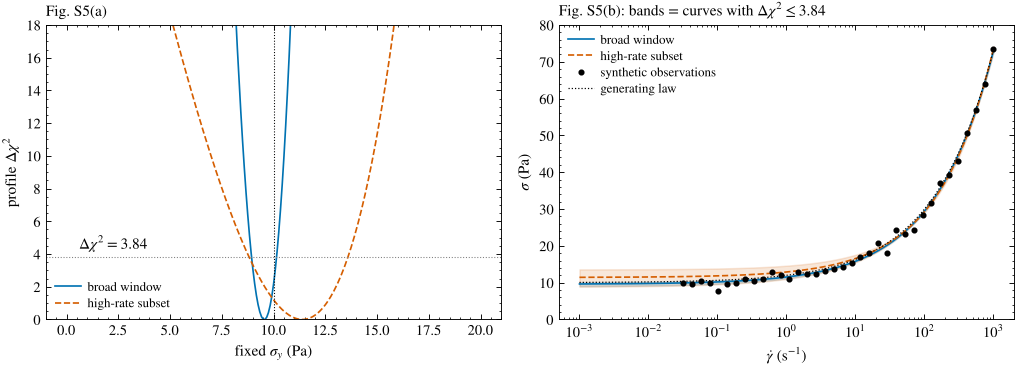

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
mine5 = {}
for (lab, (chi2, pred)), col, ls in zip(PROF.items(), [C["blue"], C["red"]], ["-", "--"]):
    delta = chi2 - chi2.min(); valid = delta <= 3.84
    ax[0].plot(tys, delta, color=col, ls=ls, label=lab)
    ax[1].fill_between(gp, pred[valid].min(0), pred[valid].max(0), color=col, alpha=0.15)
    ax[1].semilogx(gp, pred[np.argmin(chi2)], color=col, ls=ls, label=lab)
    mine5[("(a)", lab)] = (tys, delta); mine5[("(b)", lab)] = (gp, pred[np.argmin(chi2)])
ax[0].axhline(3.84, color="grey", lw=0.7, ls=":"); ax[0].axvline(10, color="k", lw=0.7, ls=":")
ax[0].text(0.6, 4.3, r"$\Delta\chi^2=3.84$")
ax[0].set(xlabel=r"fixed $\sigma_y$ (Pa)", ylabel=r"profile $\Delta\chi^2$", ylim=(0, 18)); ax[0].legend(fontsize=8.5)
ax[1].semilogx(g5, y5, "o", ms=3, color="k", label="synthetic observations")
ax[1].semilogx(gp, 10 + 2 * np.sqrt(gp), ":", color="k", lw=0.8, label="generating law")
mine5[("(b)", "synthetic observations")] = (g5, y5); mine5[("(b)", "generating law")] = (gp, 10 + 2 * np.sqrt(gp))
ax[1].set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", ylim=(0, 80)); ax[1].legend(loc="upper left", fontsize=8.5)
ax[0].set_title("Fig. S5(a)", loc="left", fontsize=10); ax[1].set_title("Fig. S5(b): bands = curves with $\\Delta\\chi^2\\leq3.84$", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

In [18]:
refS5 = pd.read_csv(FIGDATA / "figS5_uncertainty.csv", comment="#")
worst = 0.0
for (panel, lab), (x, y) in mine5.items():
    r = refS5[(refS5.panel == panel) & (refS5.series == lab)].sort_values("index")
    assert len(r) == len(x) and np.allclose(r.x.values, x, rtol=1e-9)
    assert np.allclose(r.y.values, y, rtol=1e-5, atol=1e-6), (panel, lab)
    worst = max(worst, np.max(np.abs(r.y.values - y)))
print(f"Fig. S5: profiles, best-fit curves, observations and generating law agree with figS5_uncertainty.csv "
      f"(largest absolute difference {worst:.1e}; tolerance rtol 1e-5, atol 1e-6). The shaded bands are not compared.")

Fig. S5: profiles, best-fit curves, observations and generating law agree with figS5_uncertainty.csv (largest absolute difference 4.7e-07; tolerance rtol 1e-5, atol 1e-6). The shaded bands are not compared.


Note what the bands are: the envelope of fitted mean responses whose profile $\Delta\chi^2\le3.84$. This is a one-parameter profile-envelope construction, not a simultaneous three-parameter confidence region and not a prediction interval for new observations. Even so, panel (b) shows the practical message: the high-rate subset constrains the curve well where it has data and poorly below 1 s$^{-1}$, which is where restart and arrest are decided.

## 7. Practical advice

Collected from Secs. VI A, VI D–F and Supplementary Notes S6 and S18 of the review:

1. **State the protocol and the window.** An HB fit to a steady (descending) sweep gives a dynamic, model-dependent intercept, which is usually the lowest of the common yield-stress measures (Table VII; Dinkgreve et al. 2016). Report the rate window, because $\sigma_y$, $K$ and $n$ all move with it.
2. **Make the low-rate points trustworthy before trusting $\sigma_y$.** They constrain the intercept and are the ones most affected by slip, nonstationarity, delayed yielding, banding below a critical rate, inertia and bearing friction. Use roughened tools or a slip check, and record stress against time at the lowest rates.
3. **Choose the weights from the noise**, measured by replicates or calibration, not from the answer they produce. Logarithmic residuals suit relative errors.
4. **Use the one-dimensional profile in $n$** (Mullineux 2008) or multistart constrained nonlinear least squares, and enforce $\sigma_y\ge0$ by recomputing on the boundary, not by clipping. (Kelessidis et al. 2006 enforced a positive yield stress with a golden-section search on $\sigma_y$ combined with linear regression for $K$ and $n$.)
5. **Report intervals from the profile likelihood**, a bootstrap over independent units (whole sweeps, loadings, batches, not individual points), or a posterior with physical support, rather than the local covariance alone.
6. **Ask whether the yield stress is resolved**: is a zero-yield power law measurably worse under the noise model? Is HB measurably better than Bingham when $n$ is close to one? Bayesian model selection (Freund and Ewoldt 2015) makes such comparisons explicit. For a thixotropic material, include a flow curve with a critical shear rate among the candidates.
7. **Reparameterize for comparison**: $\sigma = \sigma_y + A(\dot\gamma/\dot\gamma_*)^n$ with $\dot\gamma_*$ in the application window (Saasen and Ytrehus 2020), or $\sigma = \sigma_y[1+(\dot\gamma/\dot\gamma_y)^n]$ (Nelson and Ewoldt 2017), so that the parameters have consistent units.
8. **Budget the systematic error.** Single-sweep intervals are only lower bounds. A defensible characterization adds replicate loadings, independent batches, a slip check and a stationarity record, and computes intervals from the spread across loadings.
9. **Propagate jointly.** For an application output $H(\boldsymbol\theta)$, $\mathrm{Var}(H)\simeq\nabla H^T\Sigma_\theta\nabla H$, Eq. (17), *with* the covariance terms; varying each parameter between its marginal bounds generates combinations the data never supported. Outputs inside the calibrated range (e.g. pipe pressure at high flow rate) can be well determined even when $\sigma_y$ is not, while restart and arrest inherit the full yield-stress uncertainty.
10. **Separate calibration from validation**: agreement with the fitted data is calibration; validation needs an independent condition (another radius, flow-rate range, geometry or protocol).

For measured flow curves, the package at https://github.com/ktwyw/herschel-bulkley-determinant-fit implements Mullineux's determinant method with constraints, confidence intervals and model comparison, and includes a browser app.

## Try it yourself

**Exercise 1 — how lucky was Fig. 7?** Repeat the three fits of Sec. 2 for 100 different random seeds and plot histograms of $\sigma_y$ for fits (i), (ii) and (iii). Which choice has the largest bias, and which the largest scatter?
*Hint:* wrap the data generation and the three `curve_fit` calls in a function of the seed; `curve_fit` may occasionally hit a bound, so keep the bounds of the script.

<details><summary>Solution</summary>

```python
def three_fits(seed):
    r = np.random.default_rng(seed)
    t = hb(gd, **TRUE) * (1 + 0.05 * r.standard_normal(gd.size))
    return [curve_fit(logmodel, gd, np.log(t), p0=p0, bounds=bounds)[0][0],
            curve_fit(logmodel, gd[high], np.log(t[high]), p0=p0, bounds=bounds)[0][0],
            curve_fit(model, gd, t, p0=p0, bounds=bounds)[0][0]]
sy_mc = np.array([three_fits(s) for s in range(100)])
for lab, col in zip(FITS, sy_mc.T):
    print(f"{lab:24s} mean {col.mean():5.2f} Pa, bias {col.mean() - 10:+.2f} Pa, SD {col.std():.2f} Pa")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(sy_mc, bins=30, label=list(FITS)); ax.set_xlabel(r"fitted $\sigma_y$ (Pa)"); ax.legend(fontsize=8); plt.show()
```
Over seeds 0–99 all three choices are nearly unbiased: mean $\sigma_y$ = 9.99 Pa for (i), 9.78 Pa for (ii) and 10.00 Pa for (iii). The scatter differs greatly: the standard deviation is 0.21 Pa for (i), 0.35 Pa for (iii) and 1.96 Pa for (ii). Fit (ii) has both the largest bias, $-0.22$ Pa, and by far the largest scatter. The 7.8 Pa of Fig. 7 is a draw about one standard deviation below the mean of (ii), so Fig. 7 is typical, not unlucky: discarding the low rates makes the intercept about ten times less precise than fit (i).
</details>

**Exercise 2 — the valley for a narrow window.** Recompute the RMS map of Sec. 3 using only $\dot\gamma\ge10$ s$^{-1}$ and draw the 6% contour on top of the full-window map. How much longer is the valley?

<details><summary>Hint</summary>

Copy the double loop of Sec. 3 with `gd[high]`, `tau[high]` and `w[high]`, then `ax.contour(TY, NN, RMS_high, levels=[6], colors="red")`.
</details>

<details><summary>Solution</summary>

```python
RMS_high = np.zeros_like(RMS)
for i, nn in enumerate(NN):
    X = gd[high]**nn; wh = w[high]
    for j, tt in enumerate(TY):
        yv = tau[high] - tt
        Kopt = max(np.sum(wh**2 * X * yv) / np.sum(wh**2 * X * X), 1e-9)
        RMS_high[i, j] = np.sqrt(np.mean(((yv - Kopt * X) * wh)**2)) * 100
for lab, Rm in [("full window", RMS), ("high-rate window", RMS_high)]:
    ins = Rm < 6
    print(f"{lab}: 6% region spans sigma_y {TY[ins.any(0)].min():.1f}-{TY[ins.any(0)].max():.1f} Pa, "
          f"n {NN[ins.any(1)].min():.2f}-{NN[ins.any(1)].max():.2f}")
fig, ax = plt.subplots(figsize=(5.2, 4))
ax.contourf(TY, NN, RMS, levels=np.linspace(4, 32, 15), cmap="viridis_r", extend="max")
ax.contour(TY, NN, RMS, levels=[6], colors="white"); ax.contour(TY, NN, RMS_high, levels=[6], colors="red")
ax.set(xlabel=r"$\sigma_y$ (Pa)", ylabel="$n$"); plt.show()
```
With all rates, the region where the RMS residual is below 6% spans $\sigma_y$ = 9.0–10.9 Pa and $n$ = 0.41–0.55. With $\dot\gamma\ge10$ s$^{-1}$ only, it spans $\sigma_y$ = 0–12.5 Pa and $n$ = 0.31–0.55: the valley is about seven times longer in $\sigma_y$ and reaches the boundary $\sigma_y = 0$. The high-rate data alone cannot tell a 10 Pa yield stress from none.
</details>

**Exercise 3 — profile for the Fig. 7 data.** Build a profile in $\sigma_y$ for the Fig. 7 data with logarithmic residuals and an *estimated* noise level (use the residual standard deviation of fit (i), $s^2 = \mathrm{SSE}/(N-3)$, in place of the known $\varsigma$). Compare the 95% intervals for the full window and the high-rate window, and check whether the true value 10 Pa lies inside both.

<details><summary>Solution</summary>

```python
r_i = np.log(model(gd, *p_log)) - np.log(tau)
s2 = np.sum(r_i**2) / (gd.size - 3)                       # estimated noise variance of the log stress
TYP = np.linspace(0, 14, 281)
def log_profile(mask):
    prof = []
    for ty in TYP:                                        # refit K and n at fixed sigma_y, three starts
        prof.append(min(np.sum(least_squares(lambda z: np.log(ty + z[0] * gd[mask]**z[1]) - np.log(tau[mask]),
                                             [2, n0], bounds=([1e-6, 0.05], [100, 2])).fun**2) for n0 in (0.3, 0.5, 0.8)) / s2)
    return np.array(prof) - min(prof)
print("s =", np.sqrt(s2))
for lab, m in [("full window", np.ones_like(gd, bool)), ("high-rate window", high)]:
    inside = TYP[log_profile(m) <= 3.84]
    print(f"{lab}: 95% profile interval {inside.min():.2f}-{inside.max():.2f} Pa")
```
The estimated noise is $s = 0.044$ (about 4.4% in stress, against the 5% used to generate the data). The 95% profile interval is 9.65–10.35 Pa for the full window and 2.25–11.55 Pa for the high-rate window. Both contain the true 10 Pa, but the second is more than ten times wider and is asymmetric about its minimum at 7.8 Pa, the value of fit (ii). Because the noise level is estimated from the same data, these intervals are approximate.
</details>

**Exercise 4 — propagate to a pipe.** For fits (i) and (ii), compute the wall stress needed to drive $Q = 10^{-8}$ and $10^{-4}$ m$^3$/s through a pipe of radius 1 cm (apparent wall rates of about 0.01 and 130 s$^{-1}$) with `pressure_gradient` from `hb_prediction.py` (import it from the `scripts` folder). At which flow rate do the two calibrations disagree more, and why?

<details><summary>Solution sketch for Exercise 4</summary>

```python
from hb_prediction import pressure_gradient
for Qv in [1e-8, 1e-4]:
    G = [pressure_gradient(Qv, 0.01, *FITS[k]) for k in ["(i) log, all rates", "(ii) log, high rates"]]
    print(Qv, [g * 0.01 / 2 for g in G])
```
At the low flow rate the wall stress is close to the yield stress (about 10.8 and 8.9 Pa), so the two calibrations differ by about 20%, nearly their difference in $\sigma_y$; at the high flow rate the wall rate lies inside both calibration windows and they agree to about 2% (compare Supplementary Note S5 and Sec. VI F).
</details>

## Key points
- The HB fit is ill-conditioned: $\sigma_y$ and $n$ trade off along a long, curved valley, so the estimates depend on the rate window, the weighting and a few low-rate points (Fig. 7).
- At fixed $n$ the model is linear in $\sigma_y$ and $K$; scanning $n$ (Mullineux 2008) turns the fit into a one-dimensional problem and exposes the valley as $(\sigma_y(n), n)$.
- The determinant of the normal equations is $(\sum w)^2$ times the weighted variance of $\dot\gamma^n$: a narrow window makes the problem nearly singular whatever the optimizer.
- Constraints such as $\sigma_y\ge0$ must be imposed by recomputing on the boundary, not by clipping.
- The weighting is a noise model; choose it from replicate or calibration data.
- Profile-likelihood intervals (or bootstraps over independent units) are preferable to the local covariance; even they are lower bounds when systematic errors (slip, drift, loading, batch) dominate.

## References

The review and its repository:
- Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review
- *herschel-bulkley-determinant-fit*: Python package and browser app implementing Mullineux's determinant method for HB flow curves. https://github.com/ktwyw/herschel-bulkley-determinant-fit

- G. Mullineux (2008). Non-linear least squares fitting of coefficients in the Herschel–Bulkley model. *Applied Mathematical Modelling* **32**, 2538–2551. https://doi.org/10.1016/j.apm.2007.09.010
- V. C. Kelessidis, R. Maglione, C. Tsamantaki and Y. Aspirtakis (2006). Optimal determination of rheological parameters for Herschel–Bulkley drilling fluids and impact on pressure drop, velocity profiles and penetration rates during drilling. *Journal of Petroleum Science and Engineering* **53**, 203–224. https://doi.org/10.1016/j.petrol.2006.06.004
- A. Saasen and J. D. Ytrehus (2020). Viscosity models for drilling fluids—Herschel–Bulkley parameters and their use. *Energies* **13**, 5271. https://doi.org/10.3390/en13205271
- A. Z. Nelson and R. H. Ewoldt (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**, 7578–7594. https://doi.org/10.1039/C7SM00758B
- J. B. Freund and R. H. Ewoldt (2015). Quantitative rheological model selection: Good fits versus credible models using Bayesian inference. *Journal of Rheology* **59**, 667–701. https://doi.org/10.1122/1.4915299
- M. Dinkgreve, J. Paredes, M. M. Denn and D. Bonn (2016). On different ways of measuring “the” yield stress. *Journal of Non-Newtonian Fluid Mechanics* **238**, 233–241. https://doi.org/10.1016/j.jnnfm.2016.11.001
- W. H. Herschel and R. Bulkley (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034

### Further reading

- E. Magnon and E. Cayeux (2021). Precise Method to Estimate the Herschel–Bulkley Parameters from Pipe Rheometer Measurements. *Fluids* **6**, 157. https://doi.org/10.3390/fluids6040157